# **About Dataset**

The Brain Tumor MRI Data dataset, is a curated collection of MRI scans for brain tumor classification. It contains four classes: Glioma Tumor, Meningioma Tumor, Pituitary Tumor, and No Tumor.

In [1]:
from IPython.display import Image, display
display(Image(url="https://www.osmosis.org/_next/image?url=https%3A%2F%2Fd16qt3wv6xm098.cloudfront.net%2Fv34RyHfDRQeNNq2QMS_f3DAEQKCCM-MR%2F_.jpg&w=3840&q=75"))

In [2]:
from IPython.display import Image, display
display(Image(url="https://www.universitycancer.com/wp-content/uploads/2023/05/ucbc-may-blog-2.jpg"))

# **Importing Libraries**

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16,VGG19,ResNet50,ResNet101,InceptionV3,EfficientNetB0,ConvNeXtLarge,DenseNet121,DenseNet201,NASNetLarge
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D,Dense,Flatten,Dropout,GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
import os
import random
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping


In [4]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
# Define the path
data_path = '/kaggle/input/brain-tumor-mri-data/brain-tumor-mri-dataset'

# Checking the folders
classes = os.listdir(data_path)
print("Classes in the dataset:", classes)


Classes in the dataset: ['pituitary', 'notumor', 'meningioma', 'glioma']


In [6]:
# Count images in each class
for category in classes:
    path = os.path.join(data_path, category)
    print(f"Number of images in '{category}': {len(os.listdir(path))}")

Number of images in 'pituitary': 1757
Number of images in 'notumor': 2000
Number of images in 'meningioma': 1775
Number of images in 'glioma': 1621


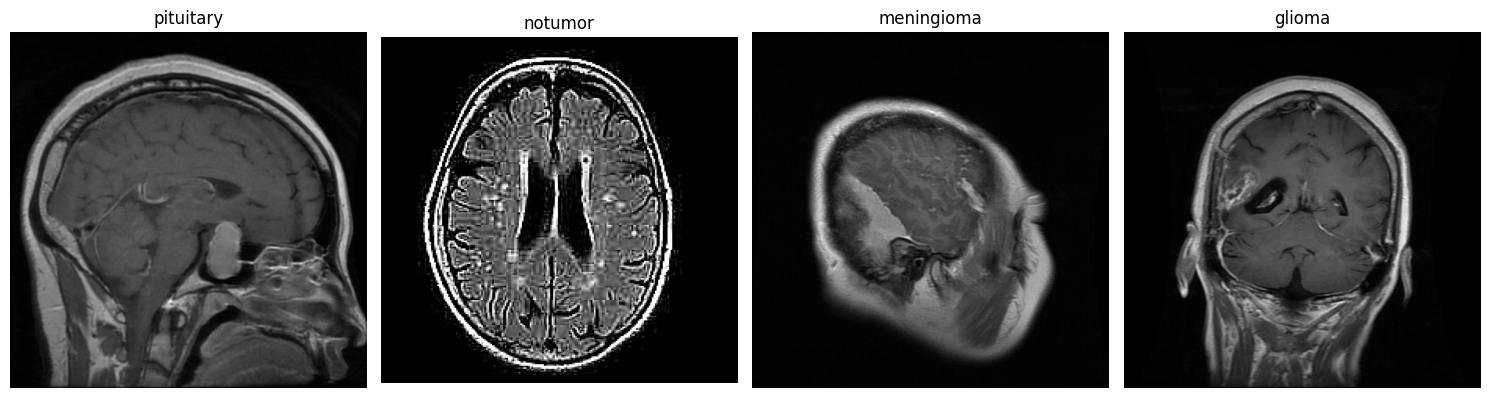

In [7]:
# Display some sample images
fig, ax = plt.subplots(1, 4, figsize=(15, 5))

for i, category in enumerate(classes):
    path = os.path.join(data_path, category)
    image_path = random.choice(os.listdir(path))
    img = cv2.imread(os.path.join(path, image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax[i].imshow(img)
    ax[i].set_title(category)
    ax[i].axis("off")

plt.tight_layout()
plt.show()


Unique Image Shapes for Each Class:
        Class          Shape
0   pituitary  (512, 512, 3)
1     notumor  (630, 630, 3)
2  meningioma  (512, 512, 3)
3      glioma  (512, 512, 3)


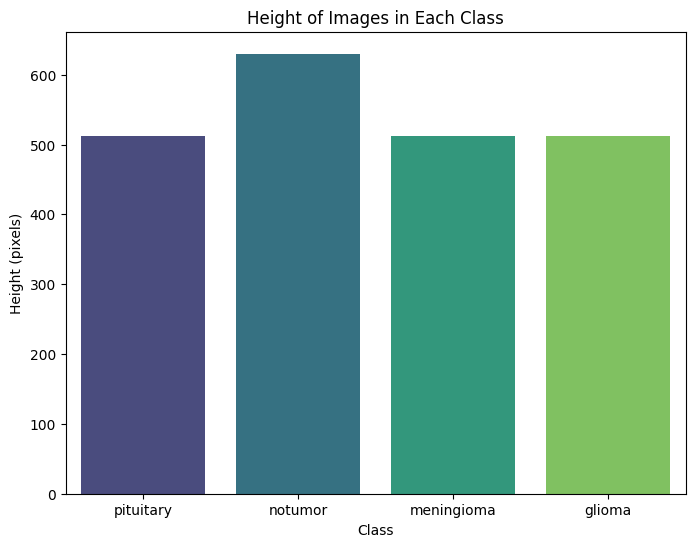

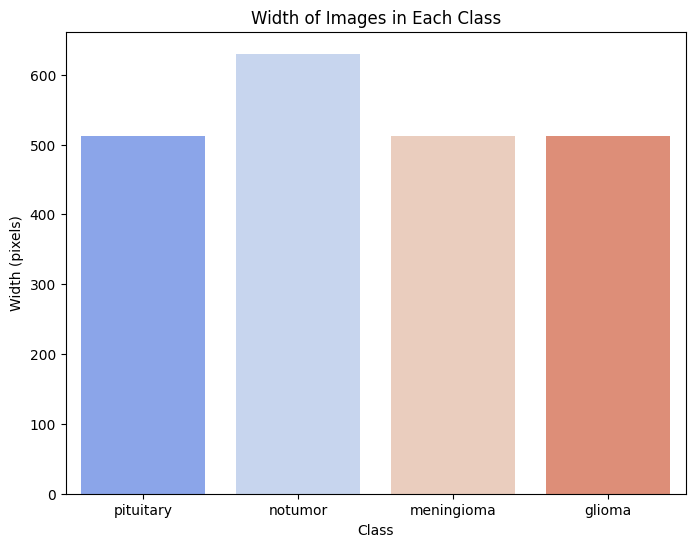

In [8]:
# Dictionary to store shapes for each class
class_shapes = {}

# Loop through each class to get the shape of one image per class
for category in classes:
    path = os.path.join(data_path, category)
    image_path = random.choice(os.listdir(path))  # Select a random image
    img = cv2.imread(os.path.join(path, image_path))  # Read the image
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert to RGB
    
    if img is not None:  # Ensure image is valid
        class_shapes[category] = img.shape  # Store the shape (Height, Width, Channels)

# Convert the shapes to a DataFrame for better visualization
shapes_df = pd.DataFrame(class_shapes.items(), columns=["Class", "Shape"])

# Display the DataFrame
print("Unique Image Shapes for Each Class:")
print(shapes_df)

# Plot the results
plt.figure(figsize=(8, 6))
sns.barplot(x="Class", y=shapes_df["Shape"].apply(lambda x: x[0]), data=shapes_df, palette="viridis")
plt.title("Height of Images in Each Class")
plt.ylabel("Height (pixels)")
plt.xlabel("Class")
plt.show()

plt.figure(figsize=(8, 6))
sns.barplot(x="Class", y=shapes_df["Shape"].apply(lambda x: x[1]), data=shapes_df, palette="coolwarm")
plt.title("Width of Images in Each Class")
plt.ylabel("Width (pixels)")
plt.xlabel("Class")
plt.show()


In [9]:
# List to store paths of corrupted images
corrupted_images = []

# Loop through each class/category
for category in classes:
    # Get the path of the current category
    category_path = os.path.join(data_path, category)
    # Loop through all images in the category
    for img_name in os.listdir(category_path):
        img_path = os.path.join(category_path, img_name)  # Full image path
        img = cv2.imread(img_path)  # Try to read the image
        
        if img is None:  # If the image is unreadable
            corrupted_images.append(img_path)  # Add to the list

# Print the results
if corrupted_images:  # If there are corrupted images
    print(f"Number of corrupted images: {len(corrupted_images)}")
    print("Corrupted image paths:")
    for path in corrupted_images:
        print(path)
else:
    print("All images are valid!")


All images are valid!


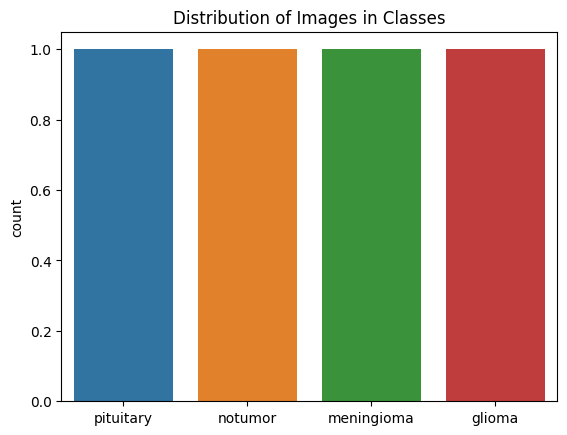

In [10]:
sns.countplot(x=classes)
plt.title("Distribution of Images in Classes")
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
import shutil

# Create directories for split data
split_base = '/kaggle/working/split_data'
split_dirs = ['train', 'test', 'valid']

for split in split_dirs:
    for category in classes:
        os.makedirs(os.path.join(split_base, split, category), exist_ok=True)

# Split and move data
train_ratio, valid_ratio = 0.7, 0.15  # 70% train, 15% validation, 15% test

for category in classes:
    category_path = os.path.join(data_path, category)
    images = os.listdir(category_path)
    
    # Split into train, validation, and test
    train_imgs, test_imgs = train_test_split(images, test_size=0.3, random_state=42)
    valid_imgs, test_imgs = train_test_split(test_imgs, test_size=0.5, random_state=42)
    
    # Copy images to respective folders
    for img_name in train_imgs:
        shutil.copy(os.path.join(category_path, img_name), os.path.join(split_base, 'train', category))
    for img_name in valid_imgs:
        shutil.copy(os.path.join(category_path, img_name), os.path.join(split_base, 'valid', category))
    for img_name in test_imgs:
        shutil.copy(os.path.join(category_path, img_name), os.path.join(split_base, 'test', category))

print("Data successfully split into train, test, and validation sets!")


Data successfully split into train, test, and validation sets!


In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Data augmentation for training
train_datagen = ImageDataGenerator(rescale=1./255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
valid_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Flow data from directories
train_gen = train_datagen.flow_from_directory(
    os.path.join(split_base, 'train'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical')

val_gen = valid_datagen.flow_from_directory(
    os.path.join(split_base, 'valid'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical')

test_gen = test_datagen.flow_from_directory(
    os.path.join(split_base, 'test'),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical')


Found 5005 images belonging to 4 classes.
Found 1073 images belonging to 4 classes.
Found 1075 images belonging to 4 classes.


# **CNN Model**

In [13]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    Conv2D(256, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

# **Compile the Model**

In [14]:
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

# **Early Stopping**

In [15]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

# **Train the Model**

In [16]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100, 
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100


I0000 00:00:1734544513.846640      97 service.cc:145] XLA service 0x7bf9013c2780 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1734544513.846709      97 service.cc:153]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1734544513.846716      97 service.cc:153]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5


  1/157 ━━━━━━━━━━━━━━━━━━━━ 1:04:19 25s/step - accuracy: 0.1250 - loss: 1.3989

I0000 00:00:1734544533.883067      97 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 84/157 ━━━━━━━━━━━━━━━━━━━━ 23s 321ms/step - accuracy: 0.4010 - loss: 1.2311

2024-12-18 17:56:07.319633: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng4{k11=1} for conv (f32[13,32,222,222]{3,2,1,0}, u8[0]{0}) custom-call(f32[13,64,220,220]{3,2,1,0}, f32[64,32,3,3]{3,2,1,0}), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardInput", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kNone","side_input_scale":0,"leakyrelu_alpha":0}} is taking a while...
2024-12-18 17:56:07.742958: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 1.423523356s
Trying algorithm eng4{k11=1} for conv (f32[13,32,222,222]{3,2,1,0}, u8[0]{0}) custom-call(f32[13,64,220,220]{3,2,1,0}, f32[64,32,3,3]{3,2,1,0}), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardInput", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config

157/157 ━━━━━━━━━━━━━━━━━━━━ 91s 427ms/step - accuracy: 0.4682 - loss: 1.1311 - val_accuracy: 0.6971 - val_loss: 0.6796
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 54s 329ms/step - accuracy: 0.7037 - loss: 0.7143 - val_accuracy: 0.8071 - val_loss: 0.4970
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 325ms/step - accuracy: 0.7619 - loss: 0.6003 - val_accuracy: 0.8267 - val_loss: 0.4492
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 324ms/step - accuracy: 0.7914 - loss: 0.5487 - val_accuracy: 0.8211 - val_loss: 0.4373
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 323ms/step - accuracy: 0.8013 - loss: 0.5129 - val_accuracy: 0.8602 - val_loss: 0.3651
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 323ms/step - accuracy: 0.8208 - loss: 0.4622 - val_accuracy: 0.8481 - val_loss: 0.3771
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 54s 329ms/step - accuracy: 0.8296 - loss: 0.4246 - val_accuracy: 0.8956 - val_loss: 0.2885
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 54s 325ms/step - accuracy: 0.8586 - loss: 0.385

# **Evaluate on Test Data**

In [17]:
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 185ms/step - accuracy: 0.9746 - loss: 0.0839
Test Accuracy: 97.95%


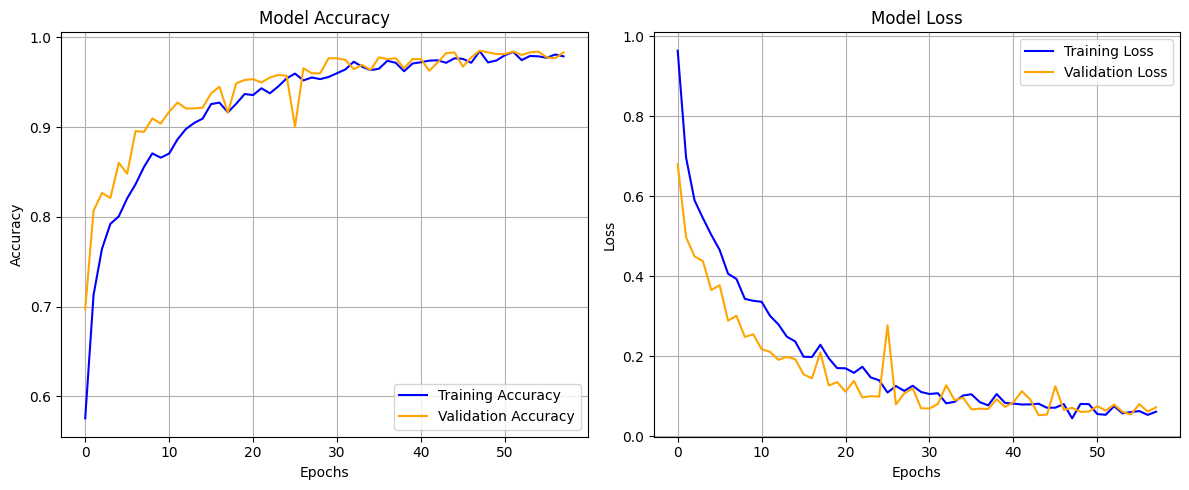

In [18]:
def plot_accuracy_and_loss(history):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()
plot_accuracy_and_loss(history)

# **VGG16**

In [19]:
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax') 
])

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [20]:
# Compile the Model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [21]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [22]:
# Train the Model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 161s 717ms/step - accuracy: 0.6609 - loss: 0.8312 - val_accuracy: 0.8565 - val_loss: 0.3907
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 78s 481ms/step - accuracy: 0.8867 - loss: 0.3176 - val_accuracy: 0.9310 - val_loss: 0.2067
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 79s 485ms/step - accuracy: 0.9353 - loss: 0.1846 - val_accuracy: 0.8872 - val_loss: 0.3117
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 79s 487ms/step - accuracy: 0.9286 - loss: 0.1905 - val_accuracy: 0.9497 - val_loss: 0.1327
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 79s 487ms/step - accuracy: 0.9577 - loss: 0.1155 - val_accuracy: 0.9702 - val_loss: 0.1121
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 79s 489ms/step - accuracy: 0.9712 - loss: 0.0883 - val_accuracy: 0.9301 - val_loss: 0.2098
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 79s 491ms/step - accuracy: 0.9698 - loss: 0.0994 - val_accuracy: 0.9739 - val_loss: 0.0733
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 79s 488ms/step - accuracy: 0.9762 

In [23]:
# Evaluate on Test Data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 17s 523ms/step - accuracy: 0.9919 - loss: 0.0450
Test Accuracy: 98.88%


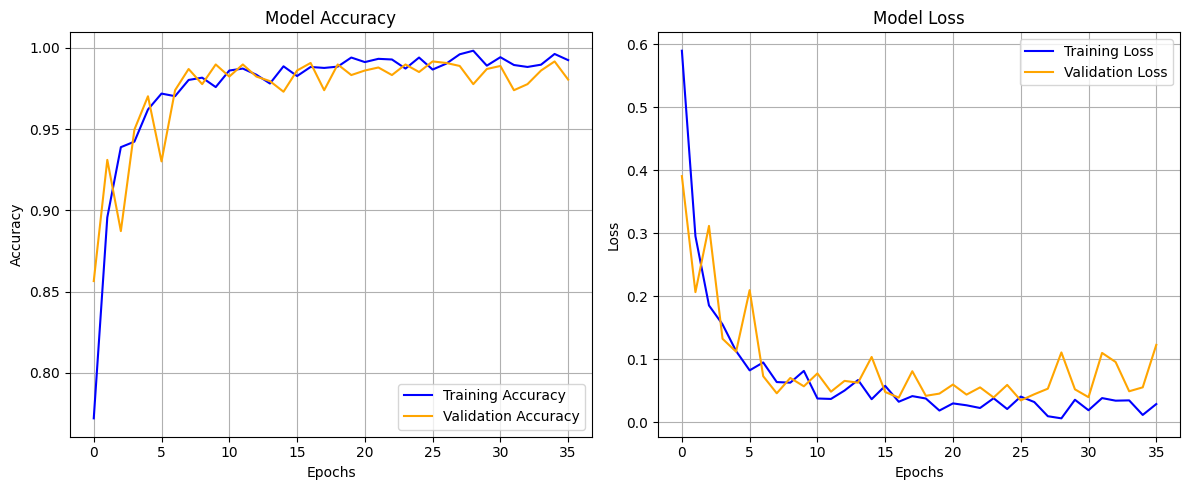

In [24]:
plot_accuracy_and_loss(history)

# **VGG19**

In [25]:
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax') 
])

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [26]:
# Compile the Model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [27]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [28]:
# Train the Model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 103s 600ms/step - accuracy: 0.5442 - loss: 1.0600 - val_accuracy: 0.8788 - val_loss: 0.3579
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 94s 581ms/step - accuracy: 0.8592 - loss: 0.3971 - val_accuracy: 0.8509 - val_loss: 0.4147
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 94s 586ms/step - accuracy: 0.9004 - loss: 0.2673 - val_accuracy: 0.8742 - val_loss: 0.3711
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 95s 591ms/step - accuracy: 0.9287 - loss: 0.2184 - val_accuracy: 0.9077 - val_loss: 0.3241
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 95s 588ms/step - accuracy: 0.9440 - loss: 0.1758 - val_accuracy: 0.9441 - val_loss: 0.1636
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 95s 587ms/step - accuracy: 0.9575 - loss: 0.1161 - val_accuracy: 0.9711 - val_loss: 0.0963
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 95s 586ms/step - accuracy: 0.9571 - loss: 0.1332 - val_accuracy: 0.9590 - val_loss: 0.1120
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 95s 587ms/step - accuracy: 0.9692 

In [29]:
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 185ms/step - accuracy: 0.9882 - loss: 0.0386
Test Accuracy: 98.70%


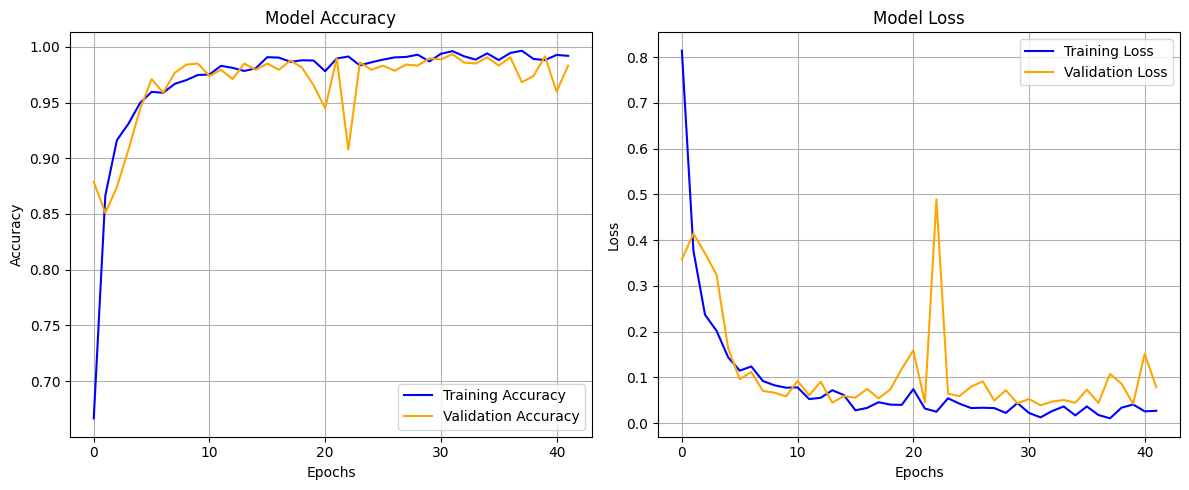

In [30]:
plot_accuracy_and_loss(history)

# **ResNet50**

In [31]:
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
# Freeze the base model's layers
base_model.trainable = False
# Add custom layers
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [32]:
#Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [33]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [34]:
# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 75s 387ms/step - accuracy: 0.2989 - loss: 1.4979 - val_accuracy: 0.4287 - val_loss: 1.1901
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 323ms/step - accuracy: 0.4213 - loss: 1.2156 - val_accuracy: 0.5666 - val_loss: 1.1402
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 322ms/step - accuracy: 0.4814 - loss: 1.1458 - val_accuracy: 0.5778 - val_loss: 1.1110
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 321ms/step - accuracy: 0.5100 - loss: 1.1231 - val_accuracy: 0.5517 - val_loss: 1.0928
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 54s 327ms/step - accuracy: 0.5229 - loss: 1.0903 - val_accuracy: 0.5899 - val_loss: 1.0790
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 323ms/step - accuracy: 0.5392 - loss: 1.0753 - val_accuracy: 0.5927 - val_loss: 1.0426
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 325ms/step - accuracy: 0.5494 - loss: 1.0699 - val_accuracy: 0.6011 - val_loss: 1.0209
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 54s 326ms/step - accuracy: 0.5616 -

In [35]:
# Evaluate on test data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 176ms/step - accuracy: 0.7655 - loss: 0.6277
Test Accuracy: 73.95%


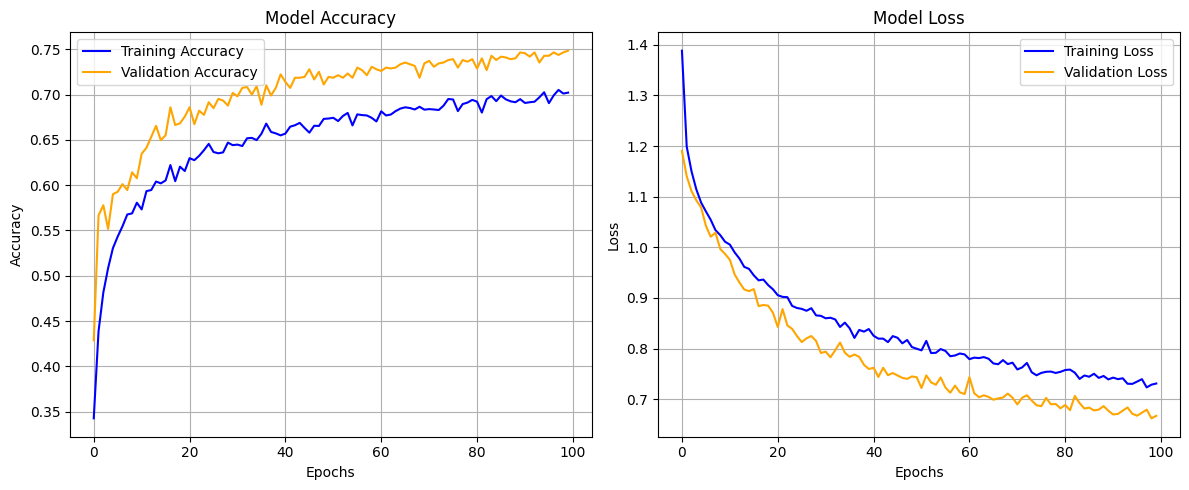

In [36]:
plot_accuracy_and_loss(history)

# **ResNet101**

In [37]:
base_model = ResNet101(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
# Freeze the base model's layers
base_model.trainable = False
# Add custom layers
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [38]:
#Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [39]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [40]:
# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 84s 417ms/step - accuracy: 0.3061 - loss: 1.5060 - val_accuracy: 0.5061 - val_loss: 1.1778
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 345ms/step - accuracy: 0.4473 - loss: 1.1989 - val_accuracy: 0.5098 - val_loss: 1.1399
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 342ms/step - accuracy: 0.5104 - loss: 1.1392 - val_accuracy: 0.5499 - val_loss: 1.1009
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 345ms/step - accuracy: 0.5338 - loss: 1.1156 - val_accuracy: 0.5582 - val_loss: 1.0686
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 350ms/step - accuracy: 0.5360 - loss: 1.0884 - val_accuracy: 0.6142 - val_loss: 1.0381
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 346ms/step - accuracy: 0.5758 - loss: 1.0597 - val_accuracy: 0.6207 - val_loss: 1.0285
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 343ms/step - accuracy: 0.5765 - loss: 1.0448 - val_accuracy: 0.6281 - val_loss: 1.0130
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 345ms/step - accuracy: 0.5782 -

In [41]:
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 218ms/step - accuracy: 0.7284 - loss: 0.7191
Test Accuracy: 73.12%


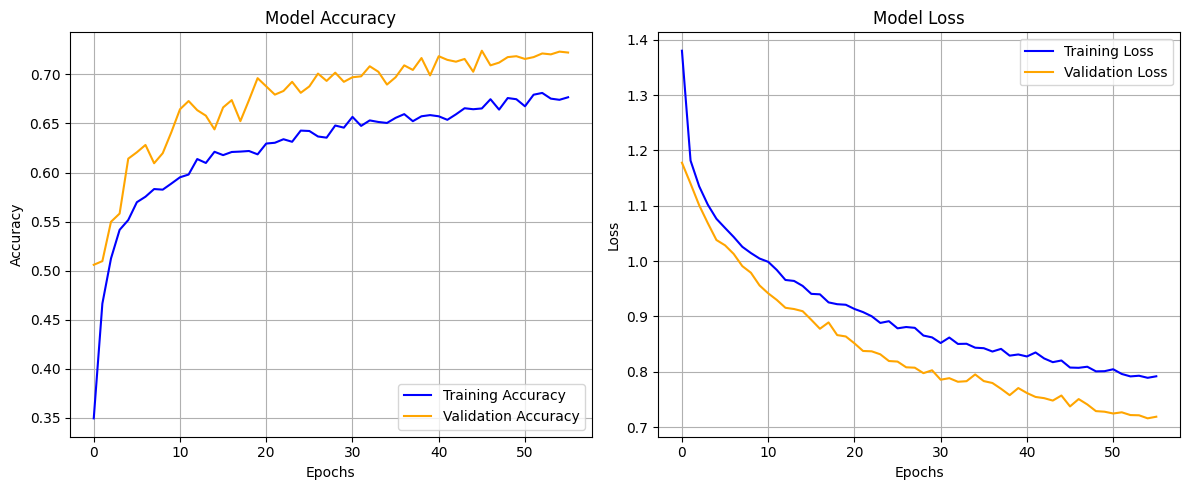

In [42]:
plot_accuracy_and_loss(history)

# **InceptionV3**

In [43]:
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
# Freeze the base model's layers
base_model.trainable = False
# Add custom layers
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [44]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [45]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [46]:
# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,  
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 85s 429ms/step - accuracy: 0.5048 - loss: 1.1711 - val_accuracy: 0.7922 - val_loss: 0.5965
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 321ms/step - accuracy: 0.7470 - loss: 0.6399 - val_accuracy: 0.8295 - val_loss: 0.5053
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 318ms/step - accuracy: 0.7864 - loss: 0.5588 - val_accuracy: 0.8425 - val_loss: 0.4446
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 317ms/step - accuracy: 0.8067 - loss: 0.4951 - val_accuracy: 0.8621 - val_loss: 0.4124
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 316ms/step - accuracy: 0.8213 - loss: 0.4793 - val_accuracy: 0.8555 - val_loss: 0.3944
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 320ms/step - accuracy: 0.8468 - loss: 0.4270 - val_accuracy: 0.8705 - val_loss: 0.3735
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 320ms/step - accuracy: 0.8589 - loss: 0.4189 - val_accuracy: 0.8770 - val_loss: 0.3550
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 318ms/step - accuracy: 0.8539 -

In [47]:
# Evaluate on test data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 8s 230ms/step - accuracy: 0.9395 - loss: 0.1736
Test Accuracy: 94.42%


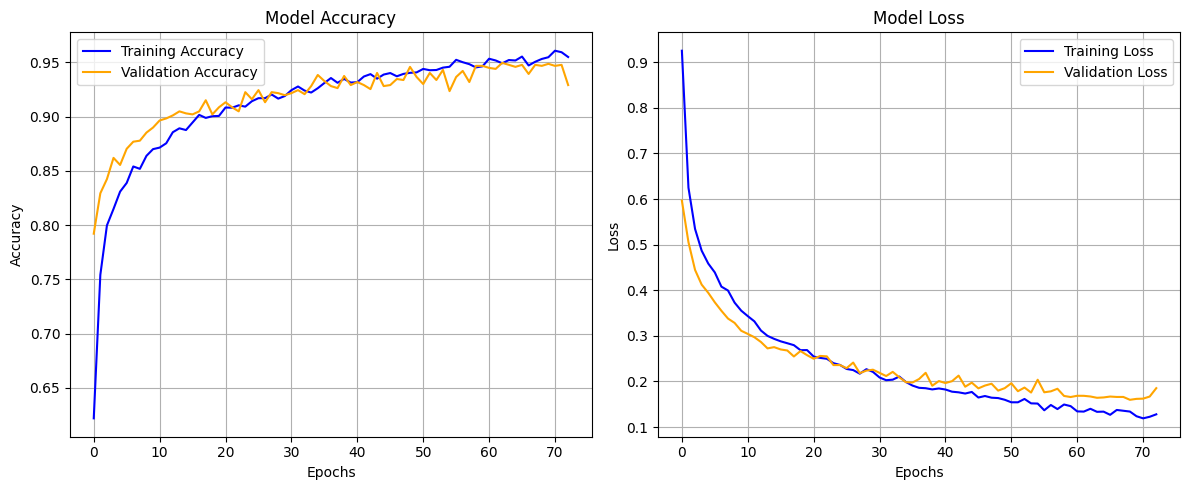

In [48]:
plot_accuracy_and_loss(history)

# **EfficientNetB0**

In [49]:
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
# Freeze the base model's layers
base_model.trainable = False
# Add custom layers
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [50]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [51]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [52]:
# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100, 
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 104s 473ms/step - accuracy: 0.2709 - loss: 1.3855 - val_accuracy: 0.2796 - val_loss: 1.3833
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 316ms/step - accuracy: 0.2692 - loss: 1.3855 - val_accuracy: 0.2796 - val_loss: 1.3833
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 318ms/step - accuracy: 0.2866 - loss: 1.3826 - val_accuracy: 0.2796 - val_loss: 1.3834
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 318ms/step - accuracy: 0.2746 - loss: 1.3846 - val_accuracy: 0.2796 - val_loss: 1.3829
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 51s 313ms/step - accuracy: 0.2727 - loss: 1.3839 - val_accuracy: 0.2796 - val_loss: 1.3830
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 51s 312ms/step - accuracy: 0.2688 - loss: 1.3845 - val_accuracy: 0.2796 - val_loss: 1.3829
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 315ms/step - accuracy: 0.2647 - loss: 1.3857 - val_accuracy: 0.2796 - val_loss: 1.3832
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 51s 312ms/step - accuracy: 0.2830 

In [53]:
# Evaluate on test data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 195ms/step - accuracy: 0.2739 - loss: 1.3836
Test Accuracy: 27.91%


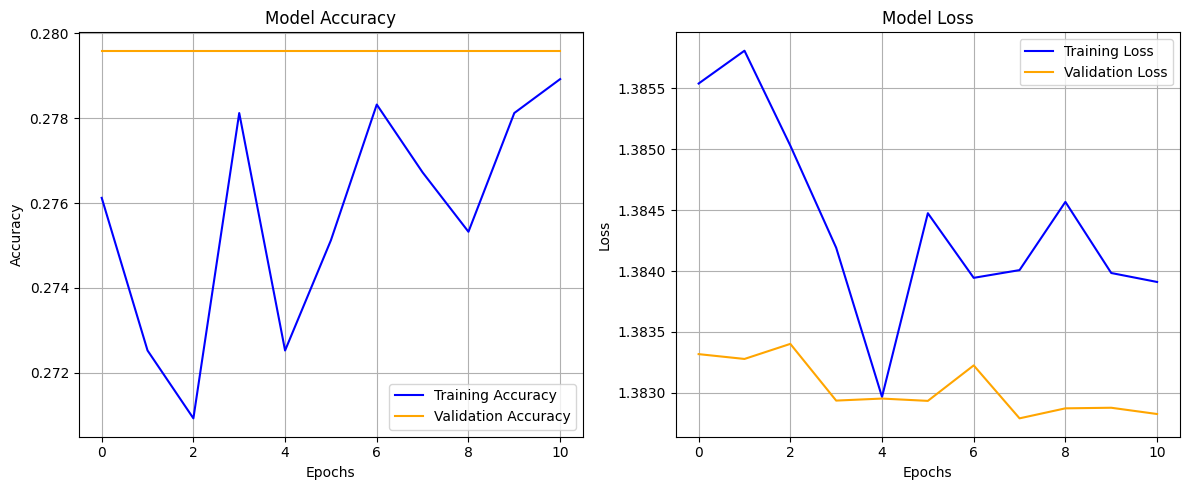

In [54]:
plot_accuracy_and_loss(history)

# **ConvNeXtLarge**

In [55]:
# Load ConvNeXtLarge pre-trained on ImageNet
base_model = ConvNeXtLarge(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base model
base_model.trainable = False

# Add custom layers for fine-tuning
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

785596384/785596384 ━━━━━━━━━━━━━━━━━━━━ 23s 0us/step


In [56]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [57]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [58]:
# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,  
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100


I0000 00:00:1734567786.773022    4998 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_12', 1048 bytes spill stores, 1044 bytes spill loads

I0000 00:00:1734567791.585190    4996 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_66', 1300 bytes spill stores, 1284 bytes spill loads



105/157 ━━━━━━━━━━━━━━━━━━━━ 37s 726ms/step - accuracy: 0.3400 - loss: 1.6099

I0000 00:00:1734567887.885879    5033 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_12', 1048 bytes spill stores, 1044 bytes spill loads

I0000 00:00:1734567888.973270    5031 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_66', 1300 bytes spill stores, 1284 bytes spill loads

I0000 00:00:1734567891.350148    5032 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_6', 1744 bytes spill stores, 1748 bytes spill loads



157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 873ms/step - accuracy: 0.3711 - loss: 1.5075

I0000 00:00:1734567972.941233    5072 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_12', 1048 bytes spill stores, 1044 bytes spill loads

I0000 00:00:1734567974.242158    5071 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_66', 1300 bytes spill stores, 1284 bytes spill loads

I0000 00:00:1734567980.030814    5069 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_6', 1744 bytes spill stores, 1748 bytes spill loads



157/157 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - accuracy: 0.3716 - loss: 1.5059 - val_accuracy: 0.6281 - val_loss: 0.9133
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 159s 996ms/step - accuracy: 0.5895 - loss: 0.9480 - val_accuracy: 0.6552 - val_loss: 0.8391
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 169s 1s/step - accuracy: 0.6120 - loss: 0.8820 - val_accuracy: 0.6757 - val_loss: 0.7663
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 170s 1s/step - accuracy: 0.6344 - loss: 0.8416 - val_accuracy: 0.6980 - val_loss: 0.7296
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - accuracy: 0.6644 - loss: 0.7964 - val_accuracy: 0.7018 - val_loss: 0.7101
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - accuracy: 0.6739 - loss: 0.7696 - val_accuracy: 0.7027 - val_loss: 0.7034
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - accuracy: 0.6829 - loss: 0.7616 - val_accuracy: 0.7279 - val_loss: 0.6613
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.6841 - loss: 0.7395 - val_accur

In [59]:
# Evaluate on test data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

33/34 ━━━━━━━━━━━━━━━━━━━━ 0s 906ms/step - accuracy: 0.8266 - loss: 0.4599

I0000 00:00:1734575039.442683    5588 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_66', 1300 bytes spill stores, 1284 bytes spill loads

I0000 00:00:1734575041.762300    5586 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_6', 1744 bytes spill stores, 1748 bytes spill loads

I0000 00:00:1734575042.229362    5589 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_12', 1048 bytes spill stores, 1044 bytes spill loads



34/34 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step - accuracy: 0.8269 - loss: 0.4595
Test Accuracy: 83.26%


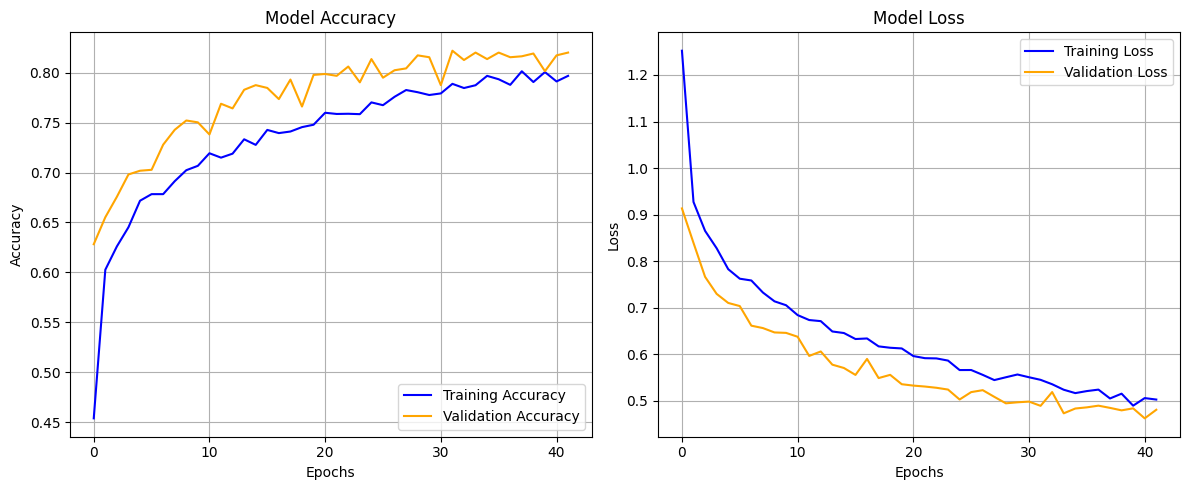

In [60]:
plot_accuracy_and_loss(history)

# **DenseNet121**

In [61]:
base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base model
base_model.trainable = False

# Add custom layers for fine-tuning
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [62]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [63]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [64]:
# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,  
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 105s 494ms/step - accuracy: 0.4352 - loss: 1.3662 - val_accuracy: 0.7996 - val_loss: 0.6084
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 322ms/step - accuracy: 0.7327 - loss: 0.6876 - val_accuracy: 0.8285 - val_loss: 0.4960
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 325ms/step - accuracy: 0.8031 - loss: 0.5486 - val_accuracy: 0.8397 - val_loss: 0.4491
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 326ms/step - accuracy: 0.8229 - loss: 0.4830 - val_accuracy: 0.8537 - val_loss: 0.4074
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 319ms/step - accuracy: 0.8380 - loss: 0.4289 - val_accuracy: 0.8537 - val_loss: 0.3958
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 320ms/step - accuracy: 0.8501 - loss: 0.4277 - val_accuracy: 0.8611 - val_loss: 0.3743
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 326ms/step - accuracy: 0.8502 - loss: 0.3959 - val_accuracy: 0.8723 - val_loss: 0.3531
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 53s 320ms/step - accuracy: 0.8665 

In [65]:
# Evaluate on test data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 12s 343ms/step - accuracy: 0.9383 - loss: 0.1677
Test Accuracy: 92.37%


In [66]:
def plot_accuracy_and_loss(history):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.tight_layout()
    plt.show()

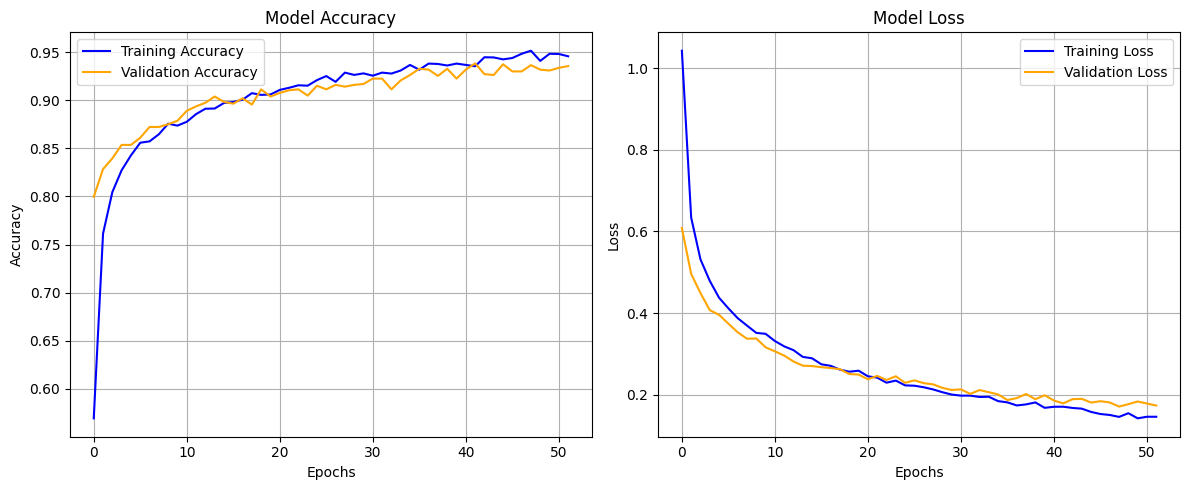

In [67]:
plot_accuracy_and_loss(history)

# **DenseNet201**

In [68]:
base_model = DenseNet201(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base model
base_model.trainable = False

# Add custom layers for fine-tuning
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [69]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [70]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [71]:
# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,  
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 131s 592ms/step - accuracy: 0.5160 - loss: 1.1445 - val_accuracy: 0.8201 - val_loss: 0.5337
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 341ms/step - accuracy: 0.7879 - loss: 0.5803 - val_accuracy: 0.8658 - val_loss: 0.4138
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 55s 339ms/step - accuracy: 0.8243 - loss: 0.4867 - val_accuracy: 0.8854 - val_loss: 0.3667
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 339ms/step - accuracy: 0.8489 - loss: 0.4204 - val_accuracy: 0.8807 - val_loss: 0.3397
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 55s 338ms/step - accuracy: 0.8647 - loss: 0.3799 - val_accuracy: 0.8844 - val_loss: 0.3174
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 343ms/step - accuracy: 0.8761 - loss: 0.3431 - val_accuracy: 0.8956 - val_loss: 0.2963
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 55s 338ms/step - accuracy: 0.8898 - loss: 0.3153 - val_accuracy: 0.8956 - val_loss: 0.2956
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 339ms/step - accuracy: 0.8881 

In [72]:
# Evaluate on test data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 16s 483ms/step - accuracy: 0.9387 - loss: 0.1461
Test Accuracy: 93.67%


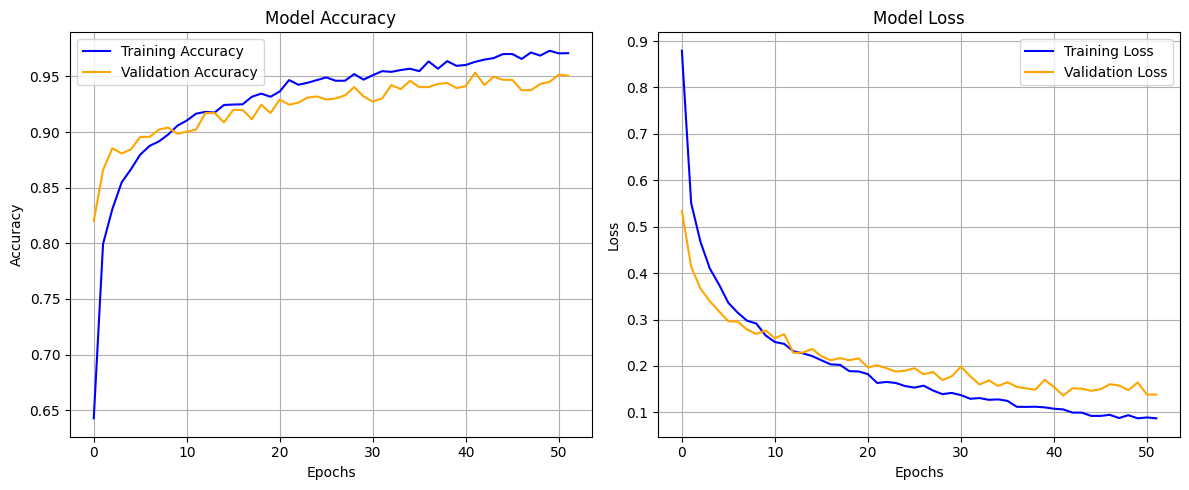

In [73]:
plot_accuracy_and_loss(history)

# **NASNetLarge**

In [74]:
base_model = NASNetLarge(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base model
base_model.trainable = False

# Add custom layers for fine-tuning
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(train_gen.num_classes, activation='softmax')
])

343610240/343610240 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step


In [75]:
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

In [76]:
early_stopping = EarlyStopping(
    #monitor='val_loss',
    monitor='val_accuracy',
    patience=10,            
    restore_best_weights=True,  
    verbose=1           
)

In [77]:
# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=100,  
    verbose=1,
    callbacks=[early_stopping]
)

Epoch 1/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 158s 709ms/step - accuracy: 0.5968 - loss: 0.9735 - val_accuracy: 0.8239 - val_loss: 0.5069
Epoch 2/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 73s 448ms/step - accuracy: 0.8074 - loss: 0.5558 - val_accuracy: 0.8481 - val_loss: 0.4326
Epoch 3/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 77s 473ms/step - accuracy: 0.8363 - loss: 0.4644 - val_accuracy: 0.8565 - val_loss: 0.3925
Epoch 4/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 79s 489ms/step - accuracy: 0.8495 - loss: 0.4157 - val_accuracy: 0.8434 - val_loss: 0.3785
Epoch 5/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 80s 496ms/step - accuracy: 0.8610 - loss: 0.3689 - val_accuracy: 0.8733 - val_loss: 0.3477
Epoch 6/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 81s 498ms/step - accuracy: 0.8688 - loss: 0.3652 - val_accuracy: 0.8453 - val_loss: 0.3813
Epoch 7/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 81s 498ms/step - accuracy: 0.8817 - loss: 0.3263 - val_accuracy: 0.8816 - val_loss: 0.3102
Epoch 8/100
157/157 ━━━━━━━━━━━━━━━━━━━━ 80s 492ms/step - accuracy: 0.8958 

In [78]:
# Evaluate on test data
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

34/34 ━━━━━━━━━━━━━━━━━━━━ 26s 764ms/step - accuracy: 0.9323 - loss: 0.1724
Test Accuracy: 93.86%


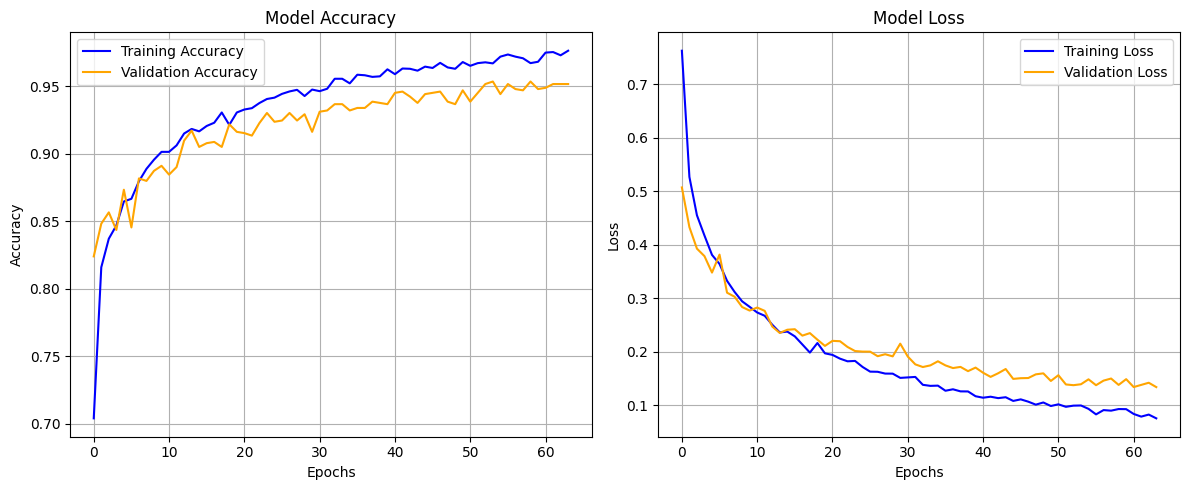

In [79]:
plot_accuracy_and_loss(history)